# Motivation over the years

**Descriptive question:** Has the percentage of students selecting “It is the most exciting” changed across survey years?

**Prediction question:** Can students' motivation choices predict the year they answered?

The analysis follows these steps: read the data → clean it → plot → split into training/test sets → train two simple classifiers → compare with a baseline.

**Methods:** we encode the motivation choices and standardize the KNN inputs. We train a **decision tree using scikit-learn**, following Lecture #07, and train **K-nearest neighbours (KNN) using scikit-learn**. The decision tree learns yes/no rules; KNN compares individual training students.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


### Read and combine the data

The shared function in `load_student_data.py` reads all four formats, removes password columns, and combines the tables. Each call returns a fresh table.

In [2]:
from load_student_data import load_student_data

# Read and combine the four survey files using the shared Python function.
students_df = load_student_data()
print("Total responses:", len(students_df))

Total responses: 223


### Extract the survey year
The file named 2023 contains answers from **2020, 2021, and 2023**. We extract the year from each timestamp instead of using the filename.

The older file uses `DD/MM/YYYY`, while the newer files start with `YYYY`. Only the year is needed for this analysis.

In [3]:
# The older file uses DD/MM/YYYY; the newer files start with YYYY.
# We only need the year, so there is no need to convert time zones.
students_df["year"] = [
    int(timestamp.split(" ")[0].split("/")[-1]) if source == 2023
    else int(timestamp[:4])
    for timestamp, source in zip(students_df["timestamp"], students_df["source_file"])
]

print(students_df["year"].value_counts().sort_index())

year
2020    50
2021     7
2023    33
2024    38
2025    50
2026    45
Name: count, dtype: int64


### Clean the reasons
Remove missing or blank answers rather than treating them as “not excited.” Convert text to lowercase and remove surrounding spaces.

Students could select several options. We check whether the exact option **“It is the most exciting”** appears anywhere in the answer. Other choices can appear alongside it. This measures selection of an option, not a person's mood.

In [4]:
# Remove missing and blank answers before creating yes/no features.
students_df["reason_clean"] = students_df["course_reason"].fillna("").str.lower().str.strip()
valid = students_df["reason_clean"] != ""
print("Excluded missing or blank answers:", (~valid).sum())
students_df = students_df.loc[valid].copy()
students_df["exciting"] = students_df["reason_clean"].str.contains(
    "it is the most exciting", regex=False
).astype(int)


Excluded missing or blank answers: 0


### How did excitement change?
Compare percentages rather than counts because the cohorts have different sizes. These are different groups of students, not the same students followed over time.

,students,selected_exciting,exciting_percent
year,,,
2020,50,22,44.0
2021,7,5,71.4
2023,33,12,36.4
2024,38,18,47.4
2025,50,31,62.0
2026,45,25,55.6


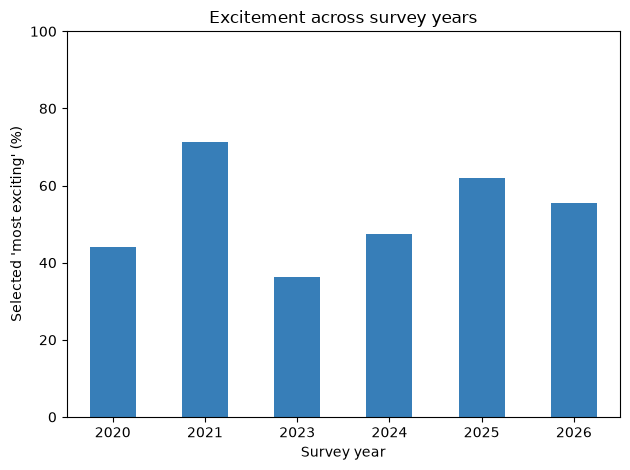

In [5]:
year_summary = students_df.groupby("year").agg(
    students=("exciting", "size"), selected_exciting=("exciting", "sum")
)
year_summary["exciting_percent"] = 100 * year_summary["selected_exciting"] / year_summary["students"]
display(year_summary.round(1))

year_summary["exciting_percent"].plot.bar(color="#377eb8", rot=0)
plt.ylabel("Selected 'most exciting' (%)")
plt.xlabel("Survey year")
plt.title("Excitement across survey years")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Preprocessing 1: encode motivation choices as numbers
Create five columns. **1 means selected, 0 means not selected.** A student can have several 1s.

Treat “business skills” and “commercially useful skills” as the same category so the model cannot simply recognize that wording change. Do not split on commas: the “not sure” option itself contains a comma. Custom text is not used as an extra feature; answers containing only custom text will have five zeros.

The model receives **only these five reasons**. It does not receive dates, year, weather, programme, height, or shoe size as inputs.

In [6]:
# The | symbol means "or": either skills phrase belongs to the same category.
reason_options = {
    "exciting": "it is the most exciting",
    "career_skills": "it'll give me business skills|it'll give me commercially useful skills",
    "mandatory": "this was mandatory for me",
    "unsure": "i'm not sure, let's see how it works out",
    "less_attractive_alternatives": "the other courses were even less attractive",
}

# pandas checks each answer; astype(int) changes True/False into 1/0.
for column, phrase in reason_options.items():
    students_df[column] = students_df["reason_clean"].str.contains(phrase).astype(int)

X = students_df[list(reason_options)].to_numpy(dtype=float)
y = students_df["year"].to_numpy()
display(students_df[list(reason_options)].head())
print("Answers with no recognized option:", (X.sum(axis=1) == 0).sum())


,exciting,career_skills,mandatory,unsure,less_attractive_alternatives
0,0,1,0,0,0
1,1,1,1,0,0
2,0,0,1,0,0
3,1,1,0,0,0
4,0,1,0,0,0


Answers with no recognized option: 11


### Split before learning from the data
Use 80% of students for training and 20% for testing. `stratify=y` keeps every year represented in both sets. The fixed random seed makes the results reproducible.

This tests prediction for another student from these **known cohorts**, not a future unseen year. Students from the same survey date can appear in both sets, so this is a limited classroom experiment rather than evidence of performance on new cohorts.

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training students:", len(y_train))
print("Test students:", len(y_test))

Training students: 178
Test students: 45


### Preprocessing 2: standardize the inputs
Use scikit-learn's `StandardScaler` to subtract each feature's training mean and divide by its training standard deviation. It also handles constant columns automatically.

`fit_transform()` learns the scaling from **training students only**. `transform()` applies the same scaling to test students, without learning from them.

KNN uses scaled inputs because it compares distances. Although the features are already 0/1, scaling gives less common choices more weight. The decision tree uses the original 0/1 inputs because it does not need scaling.


In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn the scaling from training data, then apply it to test data.
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### Train a decision tree
A decision tree learns yes/no questions about the motivation choices, then predicts a survey year.

We use `DecisionTreeClassifier` from scikit-learn, following the example in Lecture #07. `.fit()` learns the tree from training students, and `.predict()` predicts the years of test students.

The tree uses **Gini impurity** to choose splits that separate the years. We set `max_depth=3` to limit its complexity and `random_state=42` for reproducible results. The inputs are already 0/1, so no additional label encoding or scaling is needed for the tree.

In [42]:
from sklearn.tree import DecisionTreeClassifier

# Train a small decision tree using the original 0/1 motivation columns.
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

# Predict the years of students kept aside for testing.
tree_predictions = tree.predict(X_test)
years = np.unique(y_train)

print("First five tree predictions:", tree_predictions[:5])
print("First five actual years:   ", y_test[:5])

First five tree predictions: [2024 2026 2026 2026 2026]
First five actual years:    [2025 2024 2025 2025 2024]


### Add a second model: K-nearest neighbours (KNN)
KNN finds the **five training students with the closest motivation choices** and predicts the year that appears most often among them.

We use scikit-learn's `KNeighborsClassifier`. `.fit()` stores the labelled training examples, and `.predict()` finds neighbours and votes on the year. We set **K = 5** without searching for the best K using test results.

KNN uses the standardized inputs because it calculates distances. Many students have identical answer profiles, so ties between equally close neighbours can affect the predictions.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

knn_predictions = knn.predict(X_test_scaled)

print("First five predictions:", knn_predictions[:5])
print("First five actual:", y_test[:5])

First five predictions: [2024 2026 2023 2023 2023]
First five actual: [2025 2024 2025 2025 2024]


### Compare both models with a simple baseline
The baseline always predicts the most frequent year **in the training set**. Both models use the same training/test students and the same five motivation features (scaled for KNN, original 0/1 values for the tree). Accuracy is the proportion of correct predictions; we also report the number correct and show each model's confusion table.

This test set has been inspected during earlier experiments, so this comparison is **exploratory**. We fix K=5 and tree depth=3 without tuning them on these results. A fresh test set would be needed to confirm a claimed improvement.

,Method,Correct predictions,Test students,Test accuracy (%)
0,Most common year baseline,10,45,22.2
1,Decision tree (depth=3),8,45,17.8
2,KNN (K=5),10,45,22.2


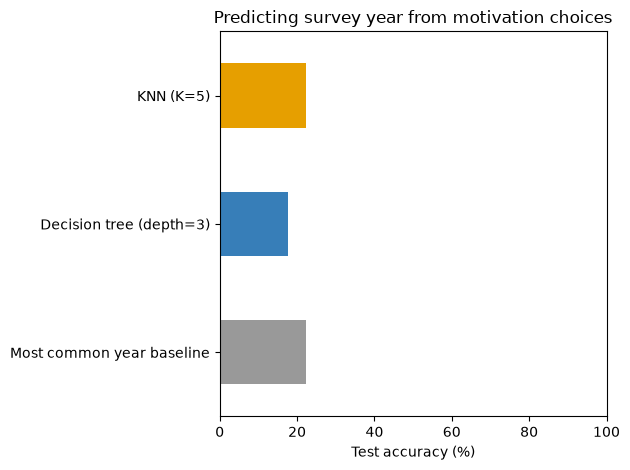

Decision tree (depth=3)


Predicted year,2020,2021,2023,2024,2025,2026
Actual year,,,,,,
2020,2,0,0,3,2,3
2021,0,0,0,0,1,0
2023,2,0,0,2,1,2
2024,1,0,0,0,1,6
2025,0,0,0,2,1,7
2026,4,0,0,0,0,5


KNN (K=5)


Predicted year,2020,2021,2023,2024,2025,2026
Actual year,,,,,,
2020,3,0,1,3,0,3
2021,0,1,0,0,0,0
2023,1,1,3,2,0,0
2024,0,0,3,1,0,4
2025,1,1,2,1,0,5
2026,0,0,7,0,0,2


In [11]:
from sklearn.metrics import accuracy_score

most_common_year = pd.Series(y_train).value_counts().idxmax()
baseline_predictions = np.full(len(y_test), most_common_year)

# Compare all methods on exactly the same test students.
all_predictions = {
    "Most common year baseline": baseline_predictions,
    "Decision tree (depth=3)": tree_predictions,
    "KNN (K=5)": knn_predictions,
}
comparison_rows = []
for name, predicted in all_predictions.items():
    correct = np.sum(predicted == y_test)
    comparison_rows.append({"Method": name, "Correct predictions": correct,
                            "Test students": len(y_test),
                            "Test accuracy (%)": 100 * accuracy_score(y_test, predicted)})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(1))

comparison.plot.barh(x="Method", y="Test accuracy (%)", legend=False,
                    color=["#999999", "#377eb8", "#e69f00"])
plt.xlabel("Test accuracy (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.title("Predicting survey year from motivation choices")
plt.tight_layout()
plt.show()

# Rows are actual years; columns are predicted years.
for name in ["Decision tree (depth=3)", "KNN (K=5)"]:
    print(name)
    confusion = pd.crosstab(
        pd.Series(y_test, name="Actual year"),
        pd.Series(all_predictions[name], name="Predicted year")
    ).reindex(index=years, columns=years, fill_value=0)
    display(confusion)

### Answers and limitations

The excitement percentage ranges from **36.4% in 2023** to **71.4% in 2021**. These are different cohorts, and 2021 contains only seven students.

On the **45 test students**, the baseline predicts **10 correctly (22.2%)**, the decision tree predicts **8 correctly (17.8%)**, and KNN predicts **10 correctly (22.2%)**. Neither model beats the baseline on this split, so motivation choices do not predict the year accurately in this experiment.

One additional correct prediction changes accuracy by about **2.2 percentage points**. This small, previously inspected test set does not establish a reliable advantage for either model.


- Some years have very few students; 2021 has only seven. Results for small groups are especially uncertain.
- The same five-option profile can occur in several years. The model cannot distinguish students with identical inputs.
- Programme composition, survey wording, and course requirements may differ across cohorts. These may explain motivation differences.
- Students answering on the same day may be similar. Our student-level split does not test generalization to independent survey days or future years.
- These simple classifiers may perform poorly. Reporting weak performance is a valid answer; it means these inputs and this method were not sufficient for accurate prediction in this test.

**Methods covered:** categorical encoding, training-only standardization, a scikit-learn decision tree, and scikit-learn KNN. Text cleaning and missing-answer handling are also included. No weather data are needed for this notebook.